<a href="https://colab.research.google.com/github/KarlaMichelleSorianoSanhez/Simulacion-II/blob/main/Ajuste_de_par%C3%A1metros_del_modelo_SIR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# <font color="#14532D">Modelo SIR: Ajuste de parámetros del modelo SIR</font>
**Alumna**: Karla Michelle Soriano Sánchez

**Instrucciones:** Elaborar en un cuaderno de Jupyter Notebook en Python el código para ajustar los parámetros del modelo SIR mediante MCMC, siguiendo los artículos proporcionados.

**Objetivo:** Estimar los parámetros $a$ (tasa de transmisión) y $b$ (tasa de recuperación) del modelo SIR que mejor describen el brote de influenza en un internado de $N=763$ estudiantes, utilizando la función $\chi^2$ para evaluar el ajuste y el algoritmo Metropolis-Hastings (MCMC) para estimar los parámetros y cuantificar su incertidumbre.



## <font color="#2E7D32">1. Modelo SIR</font>

El modelo SIR describe la propagación de una enfermedad infecciosa mediante tres ecuaciones diferenciales ordinarias no lineales:

$$
\begin{aligned}
\frac{dS}{dt} &= -aSI,\\[6pt]
\frac{dI}{dt} &= aSI-bI,\\[6pt]
\frac{dR}{dt} &= bI.
\end{aligned}
$$

Donde:

- $S(t)$: número de personas susceptibles.
- $I(t)$: número de personas infectadas.
- $R(t)$: número de personas removidas.
- $a$: tasa de transmisión.
- $b$: tasa promedio de recuperación.

La población total permanece constante:

$$
N=S(t)+I(t)+R(t),
\qquad
\frac{dN}{dt}=0.
$$

Como el sistema no tiene una solución analítica explícita, utilizaremos una solución numérica para calcular el número de infectados y posteriormente ajustar los parámetros $a$ y $b$.



## <font color="#2E7D32">2. Planteamiento del problema</font>

En 1978 se registró un brote de influenza en un internado con 763 estudiantes. A partir de los datos observados durante 15 días, buscamos determinar los parámetros $a$ y $b$ que permiten aproximar el comportamiento de los infectados.

Este es un **problema inverso**, ya que conocemos los datos y queremos determinar los parámetros del modelo que mejor los describen.

### <font color="#689F38">2.1. Datos observados</font>

| $t$ (días) | $I(t)$ | $t$ (días) | $I(t)$ | $t$ (días) | $I(t)$ |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 0 | 1 | 5 | 222 | 10 | 125 |
| 1 | 3 | 6 | 294 | 11 | 69 |
| 2 | 6 | 7 | 258 | 12 | 27 |
| 3 | 25 | 8 | 237 | 13 | 11 |
| 4 | 73 | 9 | 191 | 14 | 4 |


Las condiciones iniciales son:

$$
S(0)=762,\qquad I(0)=1,\qquad R(0)=0.
$$



### <font color="#689F38">2.2. Gráfica de los datos</font>

Primero graficamos los datos para observar cómo cambió el número de infectados durante el brote.


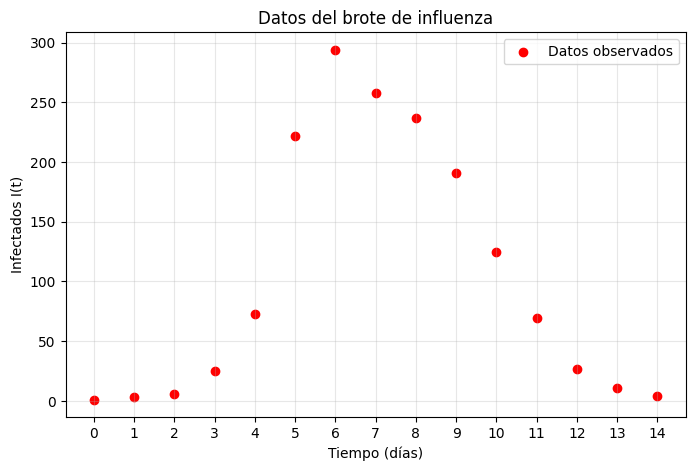

In [158]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#población total
N=763

#Días y número de infectados observados
t=np.arange(15)
I_obs=np.array([1,3,6,25,73,222,294,258,237,191,125,69,27,11,4])

#condiciones iniciales
S0, I0, R0=762, 1, 0

#Grafica de datos
plt.figure(figsize=(8, 5))
plt.scatter(t, I_obs, color="red", label="Datos observados")

plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados I(t)")
plt.title("Datos del brote de influenza")
plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### <font color="#689F38">Observación</font>

El número de infectados aumenta hasta alcanzar un máximo de 299 estudiantes en el día 6 y después disminuye hasta llegar a 5 infectados en el 14 días. Buscaremos aproximar este comportamiento mediante el modelo SIR.


## <font color="#2E7D32">3. Solución numérica del modelo SIR</font>

Para resolver el sistema de escuaciones diferenciales utilizaremos `solve_ivp`. Definimos una fucnión para el modelo SIR y otra para su solución con valores disitintos de $a$ y $b$.

Esto nos permitirá obtener el número de infectados y compararlo con los datos observados durante el ajuste.


In [159]:
#sistema de acuaiones diferenciales del modelo SIR
def SIR(t, y, a, b):
  S, I, R = y
  dS = -a * S * I
  dI = a * S * I - b * I
  dR = b * I
  return [dS, dI, dR]

#Calculamos la solución númerica para cada par (a,b)
def resolver_SIR(a, b, t_eval=t):
  solucion = solve_ivp(
    SIR, (t[0], t[-1]), [S0, I0, R0],
    args=(a, b), t_eval=t_eval
  )
  if not solucion.success:
    raise RuntimeError("No se pudo resolver el modelo SIR.")
  return solucion.y


### <font color="#689F38">3.1. Comparación inicial</font>

Para comprobar la solución numérica, utilizamos los parámetros reportados por Murray:
$$
a=0.00218,\qquad b=0.4485.
$$

Calculamos la solución del modelo con estos valores y la comparamos con los datos observados.


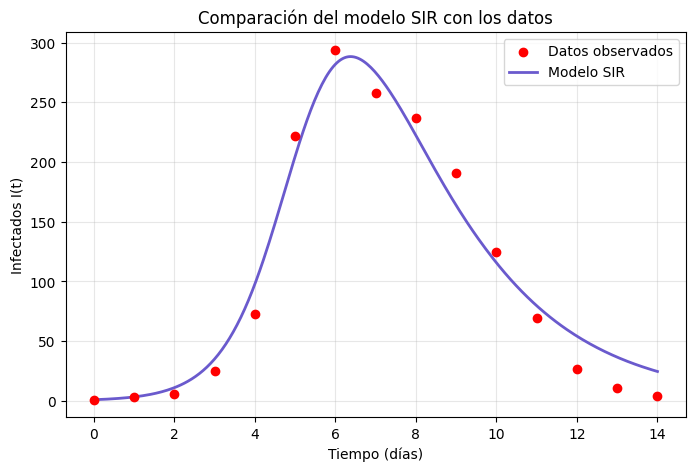

In [160]:
# Parámetros de Murray
a, b = 0.00218, 0.4485

# Más puntos para representar una curva suave
t_suave = np.linspace(0, 14, 300)

# Solución numérica del modelo SIR
S, I, R = resolver_SIR(a, b, t_suave)

# Gráfica comparativa
plt.figure(figsize=(8, 5))
plt.scatter(t, I_obs, color="red",label="Datos observados", zorder=3)
plt.plot(t_suave, I, color="slateblue",linewidth=2, label="Modelo SIR")
plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados I(t)")
plt.title("Comparación del modelo SIR con los datos")
plt.xticks(np.arange(0, 15, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### <font color="#689F38">Observación</font>

La solución númerica muestra el crecimiento y la disminución de los infectados, con un maximo cercano al observado en el día 6. Sin embargo, existen diferencias entre la curva y los datos.

Para medir estas diferencias utilizaremos la función $\chi^2$, que nos ayudará a realizar el ajuste de los parámetros.



## <font color="#2E7D32">4. Función chi-cuadrada ($\chi^2$)</font>

La función chi-cuadrada permite medir la diferencia entre los datos observados y los valores calculados por un modelo. Su expresión es:

$$
\chi^2=\sum_{i,j}(D_i-y_i(x_i|\theta))Q_{ij}(D_j-y_j(x_j|\theta)),
$$

donde $D_i$ son los datos observados, $y_i(x_i|\theta)$ los valores del modelo y $Q$ la inversa de la matriz de covarianza.

Para nuestro modelo SIR, considerando errores independientes:

$$
\chi^2(a,b)=\sum_{i=0}^{14}
\frac{[I_{\mathrm{obs}}(t_i)-I_{\mathrm{mod}}(t_i;a,b)]^2}{\sigma_i^2}.
$$

Tomaremos $\sigma_i=1$ para dar el mismo peso a todas las observaciones. Así obtenemos:

$$
\boxed{
\chi^2(a,b)=\sum_{i=0}^{14}
[I_{\mathrm{obs}}(t_i)-I_{\mathrm{mod}}(t_i;a,b)]^2
}
$$

Buscaremos los parámetros $a$ y $b$ que produzcan un menor valor de $\chi^2$. La incertidumbre que estimemos dependerá del supuesto $\sigma_i=1$.


In [161]:
#funcion chi-cuadrada
def chi2(a,b):
  # Calculamos el número de infectados con el modelo SIR
  S,I,R=resolver_SIR(a,b)
   # Diferencia entre los datos observados y el modelo
  error=I_obs-I
  return np.sum(error**2)


### <font color="#689F38">4.1. Evaluación con los parámetros de referencia</font>

Calculamos $\chi^2$ utilizando los parámetros de Murray y del algoritmo genético (GA), presentados en el artículo del modelo SIR.

| Referencia | $a$ | $b$ |
|---|---:|---:|
| Murray | 0.00218 | 0.4485 |
| Algoritmo genético (GA) | 0.00205 | 0.43552 |

Estos resultados servirán como referencia para comparar nuestro ajuste mediante MCMC.


In [162]:

# Parámetros de referencia
a1, b1 = 0.00218, 0.4485     # Murray
a2, b2 = 0.00205, 0.43552    # Algoritmo genético

# Calculamos el error de cada par
chi2_1 = chi2(a1, b1)
chi2_2 = chi2(a2, b2)

print(f"Chi-cuadrada de Murray: {chi2_1:.2f}")
print(f"Chi-cuadrada del GA: {chi2_2:.2f}")


Chi-cuadrada de Murray: 4462.07
Chi-cuadrada del GA: 10586.56



### <font color="#689F38">Observación</font>

Los parametros de Murray presentan un menor valor de $\chi^2$ que los del algoritmo genético, por lo que se aproximan mejor a los datos con esta función de error.

Utilizaremos $\chi^2$ para aplicar Metropolis-Hastings y estimar los parámetros $a$ y $b$.



## <font color="#2E7D32">5. Algoritmo Metropolis-Hastings</font>

El método MCMC permite generar muestras de una distribución de probabilidad mediante cadenas de Markov. Para ajustar los parámetros del modelo SIR utilizaremos Metropolis-Hastings.

Cada estado estará formado por un par de parámetros:

$$
X_t=(a_t,b_t).
$$

La distribución objetivo que utilizaremos es:

$$
\pi(a,b)\propto\exp\left(-\frac{\chi^2(a,b)}{2}\right),
$$

considerando errores normales independientes con $\sigma_i=1$ y parámetros en el intervalo $0<a,b<1$.

Partimos de un estado $X_t$ y generamos un candidato $Y$ mediante una distribución propuesta $q$. La probabilidad de aceptación es:

$$
\alpha(X_t,Y)=\min\left\{1,
\frac{\pi(Y)q(X_t|Y)}{\pi(X_t)q(Y|X_t)}
\right\}.
$$

Utilizaremos una propuesta normal simétrica, por lo que:

$$
\boxed{
\alpha(X_t,Y)=\min\left\{1,
\exp\left(-\frac{\chi^2(Y)-\chi^2(X_t)}{2}\right)
\right\}.
}
$$

Generamos $U\sim U(0,1)$. Si $U\leq\alpha(X_t,Y)$, aceptamos el candidato; en caso contrario, conservamos el estado anterior.

Repetimos este procedimiento para obtener las muestras que utilizaremos para estimar $a$, $b$ y su incertidumbre.



Definimos una función que genere los nuevos valores de $a$ y $b$, calcule la probabilidad de aceptación y guarde los estados de la cadena.


In [163]:
# Logaritmo de la distribución objetivo
def log_pi(X):
    a, b = X

    # Los parámetros deben estar entre 0 y 1
    if not (0 < a < 1 and 0 < b < 1):
        return -np.inf

    return -0.5 * chi2(a, b)


# Algoritmo Metropolis-Hastings
def metropolis_hastings(X0, n, s_a, s_b):

    # Guardamos los valores de a y b
    cadena = np.zeros((n + 1, 2))
    cadena[0] = X0

    X_t = np.array(X0, dtype=float)
    log_actual = log_pi(X_t)
    aceptados = 0

    if not np.isfinite(log_actual):
        raise ValueError("Los parámetros iniciales deben estar entre 0 y 1.")

    for i in range(n):

        # Proponemos un nuevo par de parámetros
        Y = X_t + np.random.normal(0, [s_a, s_b])

        # Calculamos la razón de aceptación en logaritmos
        log_nuevo = log_pi(Y)
        log_alpha = min(0, log_nuevo - log_actual)

        # Aceptamos o rechazamos la propuesta
        U = np.random.uniform(0, 1)

        if np.log(U) <= log_alpha:
            X_t = Y.copy()
            log_actual = log_nuevo
            aceptados += 1

        # Guardamos el estado de la cadena
        cadena[i + 1] = X_t

    return cadena, aceptados / n



### <font color="#689F38">5.1. Generación de las cadenas de Markov</font>

Generamos tres cadenas desde diferentes valores iniciales de $(a,b)$. Utilizaremos 1500 iteraciones por cadena y una propuesta normal simétrica, con diferentes desviaciones estándar para cada parámetro.

Los valores iniciales y las desviaciones de la propuesta se eligieron considerando el comportamiento observado en las primeras simulaciones.


In [164]:
# Semilla para reproducir los resultados
np.random.seed(42)

# Valores iniciales de las tres cadenas
X0_valores = [
    [0.002175, 0.443],
    [0.002180, 0.445],
    [0.002185, 0.447]
]

# Número de iteraciones
n = 1500

# Desviaciones estándar de la propuesta normal
s_a = 0.000002
s_b = 0.001

# Generamos las cadenas
cadenas = []
tasas = []

for X0 in X0_valores:
  cadena, tasa = metropolis_hastings(X0, n, s_a, s_b)
  cadenas.append(cadena)
  tasas.append(tasa)

cadenas = np.array(cadenas)

# Mostramos las tasas de aceptación
for i, tasa in enumerate(tasas):
  print(f"Cadena {i+1}: aceptación = {tasa:.2%}")


Cadena 1: aceptación = 50.47%
Cadena 2: aceptación = 46.60%
Cadena 3: aceptación = 45.33%



## <font color="#2E7D32">6. Análisis de convergencia</font>
Para revisar la convergencia utilizaremos el criterio de Gelman-Rubin, que compara la variación dentro de las cadenas con la variación entre ellas.

El factor se calcula mediante:

$$
\hat R=\sqrt{\frac{\widehat{\operatorname{var}}(\theta)}{W}},
$$

donde $W$ es el promedio de las varianzas dentro de las cadenas y $\widehat{\operatorname{var}}(\theta)$ es la varianza estimada.

Consideraremos el criterio:

$$
\boxed{0.97<\hat R<1.03}
$$

Descartaremos la primera mitad de cada cadena (*burn-in*) antes de calcular $\hat R$ para los parámetros $a$ y $b$.


In [165]:

# Descartamos la primera mitad de las cadenas
burn_in = n // 2
muestras = cadenas[:, burn_in + 1:, :]

# Función para calcular Gelman-Rubin
def gelman_rubin(valores):
  # Número de cadenas y muestras
  M, Nc = valores.shape
  # Variación dentro de las cadenas
  W = np.mean(np.var(valores, axis=1, ddof=1))
  # Variación entre las medias
  medias = np.mean(valores, axis=1)
  B = Nc * np.var(medias, ddof=1)
  # Varianza estimada
  var_theta = ((Nc - 1) / Nc) * W + B / Nc

  return np.sqrt(var_theta / W)


# Calculamos el factor para ambos parámetros
R_a = gelman_rubin(muestras[:, :, 0])
R_b = gelman_rubin(muestras[:, :, 1])

print(f"Gelman-Rubin para a: {R_a:.4f}")
print(f"Gelman-Rubin para b: {R_b:.4f}")

if 0.97 < R_a < 1.03 and 0.97 < R_b < 1.03:
  print("Ambos parámetros cumplen el criterio.")
else:
  print("Todavía no se cumple el criterio para ambos parámetros.")


Gelman-Rubin para a: 1.0003
Gelman-Rubin para b: 1.0040
Ambos parámetros cumplen el criterio.



### <font color="#689F38">6.1. Comportamiento de las cadenas</font>

Graficamos las tres cadenas para observar cómo cambian los parámetros durante el muestreo. La línea roja indica el final del *burn-in*.


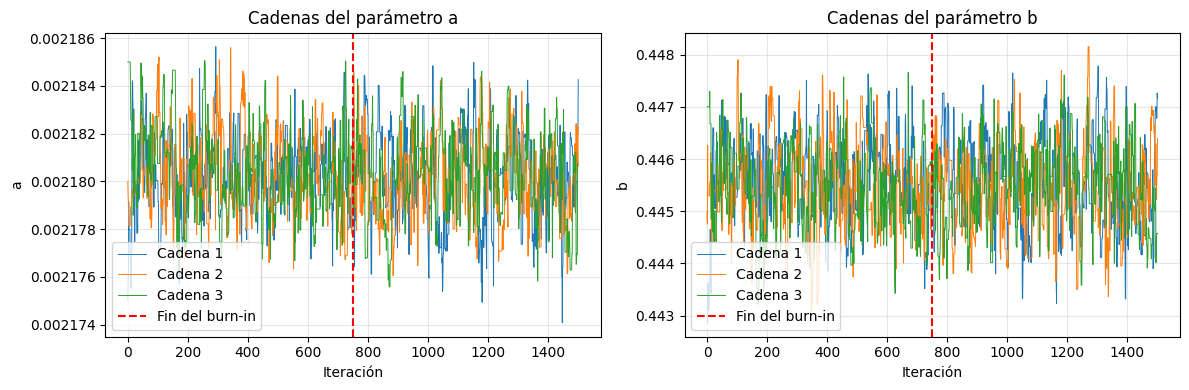

In [166]:

# Gráficas de las cadenas de a y b
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i in range(len(cadenas)):
  # Cadena del parámetro a
  axes[0].plot(cadenas[i, :, 0], linewidth=0.7,label=f"Cadena {i+1}")

  # Cadena del parámetro b
  axes[1].plot(cadenas[i, :, 1], linewidth=0.7,label=f"Cadena {i+1}")

# Señalamos el final del burn-in
for ax in axes:
  ax.axvline(burn_in, color="red", linestyle="--",label="Fin del burn-in")
  ax.set_xlabel("Iteración")
  ax.grid(alpha=0.3)
  ax.legend()

axes[0].set_title("Cadenas del parámetro a")
axes[0].set_ylabel("a")

axes[1].set_title("Cadenas del parámetro b")
axes[1].set_ylabel("b")

plt.tight_layout()
plt.show()



### <font color="#689F38">Observación</font>

Las tres cadenas de $a$ y $b$ fluctúan alrededor de valores similares después del *burn-in*.

Obtuvimos $\hat R_a=1.0003$ y $\hat R_b=1.0040$, por lo que ambos parámetros cumplen el criterio de Gelman-Rubin. Con las muestras conservadas continuaremos la estimación de los parámetros y su incertidumbre.



## <font color="#2E7D32">7. Estimación de los parámetros</font>

Con las muestras obtenidas mediante MCMC calculamos la media y la desviación estándar de $a$ y $b$. También utilizamos los percentiles 2.5 y 97.5 para obtener los intervalos del 95 % y describir la incertidumbre de ambos parámetros.


In [167]:
# Reunimos las muestras de las tres cadenas
a_muestras = muestras[:, :, 0].flatten()
b_muestras = muestras[:, :, 1].flatten()

# Calculamos las medias
a_media = np.mean(a_muestras)
b_media = np.mean(b_muestras)

# Desviaciones estándar
a_std = np.std(a_muestras)
b_std = np.std(b_muestras)

# Intervalos del 95 %
IC_a = np.percentile(a_muestras, [2.5, 97.5])
IC_b = np.percentile(b_muestras, [2.5, 97.5])

# Mostramos los resultados
print(f"a = {a_media:.8f} ± {a_std:.8f}")
print(f"Intervalo 95 % de a: [{IC_a[0]:.8f}, {IC_a[1]:.8f}]")

print(f"\nb = {b_media:.6f} ± {b_std:.6f}")
print(f"Intervalo 95 % de b: [{IC_b[0]:.6f}, {IC_b[1]:.6f}]")


a = 0.00218017 ± 0.00000178
Intervalo 95 % de a: [0.00217676, 0.00218386]

b = 0.445507 ± 0.000836
Intervalo 95 % de b: [0.444001, 0.447133]



### <font color="#689F38">7.1. Distribuciones de los parámetros</font>

Graficamos los histogramas de $a$ y $b$ para observar cómo se distribuyen las muestras. Las líneas señalan la media y los límites del intervalo del 95 %.


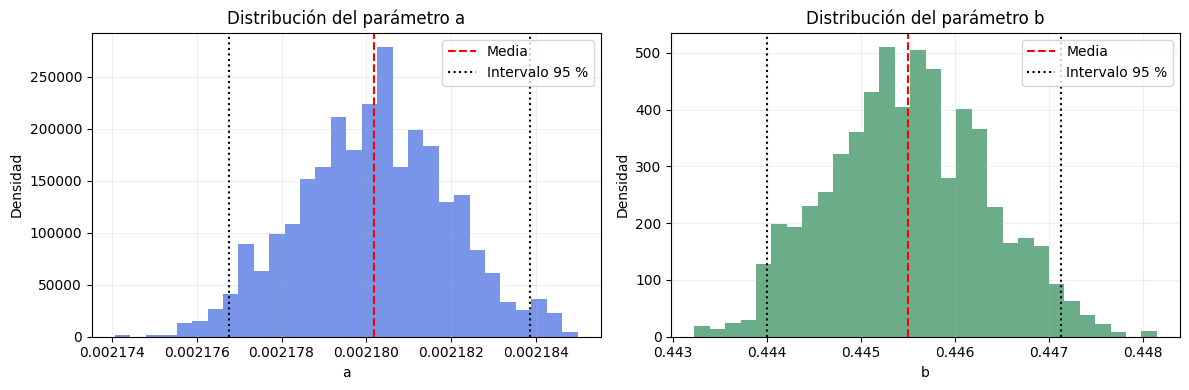

In [168]:

# Histogramas de los parámetros
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribución de a
axes[0].hist(a_muestras, bins=30, density=True, color="#4169E1", alpha=0.7)
axes[0].axvline(a_media, color="red", linestyle="--", label="Media")
axes[0].axvline(IC_a[0], color="black", linestyle=":")
axes[0].axvline(IC_a[1], color="black", linestyle=":", label="Intervalo 95 %")

# Distribución de b
axes[1].hist(b_muestras, bins=30, density=True, color="#2E8B57", alpha=0.7)
axes[1].axvline(b_media, color="red", linestyle="--", label="Media")
axes[1].axvline(IC_b[0], color="black", linestyle=":")
axes[1].axvline(IC_b[1], color="black", linestyle=":", label="Intervalo 95 %")

# Títulos y etiquetas
for ax, nombre in zip(axes, ["a", "b"]):
    ax.set_title(f"Distribución del parámetro {nombre}")
    ax.set_xlabel(nombre)
    ax.set_ylabel("Densidad")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()



### <font color="#689F38">Observación</font>

Las muestras de ambos parámetros se concentran alrededor de sus respectivas medias. Los intervalos del 95 % muestran la variación de los valores obtenidos mediante MCMC, considerando el supuesto utilizado para calcular $\chi^2$.



## <font color="#2E7D32">8. Comparación de los ajustes</font>

Con los parámetros estimados mediante MCMC, resolvemos nuevamente el modelo SIR y comparamos su solución con los datos observados.

También incluimos los parámetros de Murray y del algoritmo genético (GA) para comparar los tres ajustes mediante la función $\chi^2$.


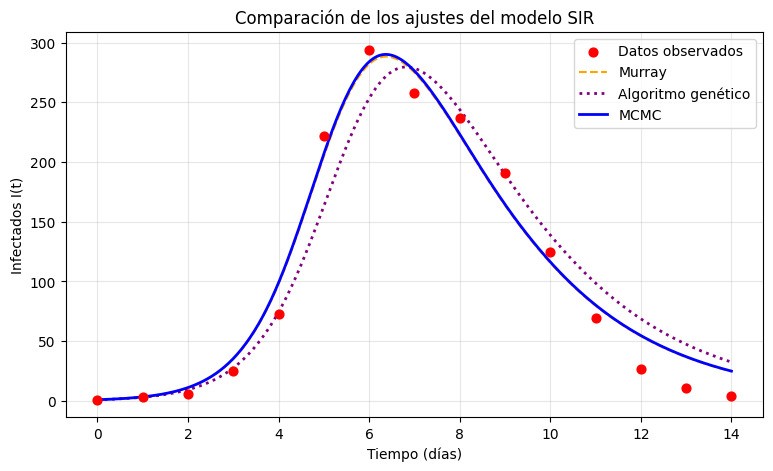

Chi-cuadrada de Murray: 4462.07
Chi-cuadrada del GA: 10586.56
Chi-cuadrada de MCMC: 4446.66


In [169]:
# Tiempo para representar las soluciones con curvas suaves
t_suave = np.linspace(0, 14, 300)

# Soluciones numéricas con los tres pares de parámetros
I_Murray = resolver_SIR(a1, b1, t_suave)[1]
I_GA = resolver_SIR(a2, b2, t_suave)[1]
I_MCMC = resolver_SIR(a_media, b_media, t_suave)[1]

# Comparamos los ajustes con los datos observados
plt.figure(figsize=(9, 5))

plt.scatter(t, I_obs, color="red", s=40,label="Datos observados", zorder=3)
plt.plot(t_suave, I_Murray, color="orange", linestyle="--",label="Murray")
plt.plot(t_suave, I_GA, color="purple", linestyle=":", linewidth=2, label="Algoritmo genético")
plt.plot(t_suave, I_MCMC, color="blue", linestyle="-",linewidth=2, label="MCMC")

plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados I(t)")
plt.title("Comparación de los ajustes del modelo SIR")
plt.xticks(np.arange(0, 15, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Comparamos los valores de chi-cuadrada
print(f"Chi-cuadrada de Murray: {chi2(a1, b1):.2f}")
print(f"Chi-cuadrada del GA: {chi2(a2, b2):.2f}")
print(f"Chi-cuadrada de MCMC: {chi2(a_media, b_media):.2f}")


### <font color="#689F38">Observación</font>

Las curvas de Murray y MCMC presentan un comportamiento muy parecido y aproximan el máximo de infectados alrededor del día 6. En cambio, el algoritmo genético muestra un máximo ligeramente desplazado hacia la derecha.

MCMC obtuvo el menor valor de $\chi^2=4446.66$, seguido de Murray ($4462.07$) y del algoritmo genético ($10586.56$). Sin embargo, las tres soluciones presentan diferencias con los datos durante los últimos días.



## <font color="#2E7D32">9. Número reproductivo y máximo de infectados</font>

Con los parámetros estimados mediante MCMC podemos calcular el número reproductivo básico $R_0$ y el máximo de infectados que predice el modelo SIR.

Como $S$, $I$ y $R$ representan el número de personas, tenemos:

$$
R_0=\frac{aN}{b}.
$$

El máximo de infectados se aproxima mediante:

$$
\frac{I_{\max}}{N}
\approx 1-\frac{1}{R_0}(1+\ln R_0).
$$

Calcularemos estos valores para compararlos con el máximo observado de 294 estudiantes.


In [170]:

# Número reproductivo con los parámetros de MCMC
R0 = a_media * N / b_media

# Máximo de infectados estimado
I_max = N * (1 - (1 + np.log(R0)) / R0)

# Comparamos con los datos observados
print(f"Número reproductivo R0: {R0:.2f}")
print(f"Máximo estimado de infectados: {I_max:.0f}")
print(f"Máximo observado: {I_obs.max()}")


Número reproductivo R0: 3.73
Máximo estimado de infectados: 289
Máximo observado: 294



## <font color="#2E7D32">Conclusión</font>

Con el algoritmo Metropolis-Hastings logramos estimar los parámetros $a$ y $b$ del modelo SIR y conocer su incertidumbre. Además, las cadenas cumplieron el criterio de Gelman-Rubin y obtuvimos el menor valor de $\chi^2=4446.66$ entre los ajustes comparados.

Con los parámetros estimados, obtuvimos un número reproductivo de $R_0=3.73$ y un máximo de 289 infectados, muy cercano a los 294 observados.
